# Notebook 05 - the regime shift
How much does error jump when a model trained on 2022-2025 meets the 2026 cars (new power units, active aero, no DRS), how much of that is just normal year-to-year change, and what kind of error is it?

1. Normal drift (control) vs the 2026 shift
2. Where the 2026 error lives: compound, team, circuit
3. Names vs measurements: which feature groups help across the rule change
4. What kind of error is left: pace level vs lap-to-lap evolution
5. Can you tell a 2026 lap from a 2025 lap? (adversarial validation)
6. Is the model honest about its uncertainty? (conformal prediction intervals)
7. Robustness: without the races run after both titles were decided Reads `data/model_table.csv.gz` and `results/model_config.json` (the feature set and parameters chosen in notebook 04).

In [1]:
import os, sys
# Run from the repo root so data/, figures/ and results/ resolve, and make src/ importable.
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, os.path.abspath('src'))

import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from f1lap.features import encode_features
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier
from f1lap.features import FEATURE_GROUPS
from f1lap.models import SEED, MODELS, COLORS, CONFIG_PATH, make_xgb, metrics, breakdown, fit_predict, evaluate_split

np.random.seed(SEED)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
cfg = json.load(open(CONFIG_PATH))   # final feature set + tuned params, chosen in notebook 04
df = pd.read_csv('data/model_table.csv.gz')
X_all = encode_features(df, cfg['groups'], cfg['team'])   # one aligned matrix, sliced per split
y_all = df['lap_delta_s']
FEATURE_COLS = list(X_all.columns)
XGB_PARAMS = cfg['xgb_params']
print('Feature set:', cfg['name'], '|', X_all.shape[1], 'features | params:', XGB_PARAMS)

Feature set: + weather (all) | 39 features | params: {'learning_rate': 0.01, 'max_depth': 5, 'min_child_weight': 400, 'n_estimators': 1000}


### 1. Normal drift (control) vs the regime shift
Every transition is measured **the same way**: train on all prior seasons, test on the next unseen season. 2024 and 2025 are normal years, our control for ordinary year-to-year drift (teams improve, drivers move). 2026 is the regulation change. Only the error *beyond* the normal-drift level is attributable to the new rules.

In [2]:
transitions = [([2022, 2023], 2024), ([2022, 2023, 2024], 2025), ([2022, 2023, 2024, 2025], 2026)]
rows = []
for tr_seasons, te_season in transitions:
    ev = evaluate_split(df, X_all, y_all, df.season.isin(tr_seasons), df.season == te_season, XGB_PARAMS)
    for n in MODELS:
        rows.append({'test_season': te_season, 'model': n, 'MAE': ev.loc[n, 'MAE'], 'RMSE': ev.loc[n, 'RMSE']})
season_mae = pd.DataFrame(rows)
print('MAE by test season (2024-2025 = normal drift, 2026 = regime change):')
season_mae.pivot(index='test_season', columns='model', values='MAE').round(3)

MAE by test season (2024-2025 = normal drift, 2026 = regime change):


model,Physics,Residual,XGBoost
test_season,,,
2024,0.827,0.504,0.495
2025,0.762,0.464,0.473
2026,1.126,0.634,0.627


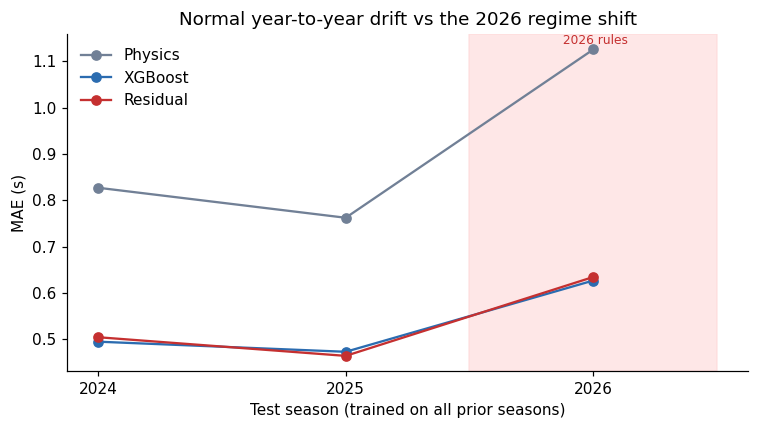

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
for n in MODELS:
    s = season_mae[season_mae.model == n]
    ax.plot(s.test_season, s.MAE, marker='o', label=n, color=COLORS[n])
ax.axvspan(2025.5, 2026.5, color='#fed7d7', alpha=0.6)
ax.text(2026, ax.get_ylim()[1], ' 2026 rules', va='top', ha='center', fontsize=8, color='#c53030')
ax.set_xticks([2024, 2025, 2026]); ax.set_xlabel('Test season (trained on all prior seasons)')
ax.set_ylabel('MAE (s)'); ax.set_title('Normal year-to-year drift vs the 2026 regime shift')
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig('figures/05_mae_by_test_season.png', dpi=150); plt.show()

**Figure 05.** With the full feature set, the two normal transitions sit around **0.47-0.50 s** for the boosted models, and that's the baseline year-to-year drift. At 2026 the error jumps to **~0.63 s**, about **+30%** above the average of the two normal years (~0.48 s), and that excess is the regime-shift effect. Compared with our first iteration (team names and 6 numeric features), every number here is about 20% lower (2026: 0.80 -> 0.63 s), but the *relative* jump has barely moved (+31% -> +30%): measuring pace makes the model better in every era rather than specifically closing the 2026 gap. The residual (physics-informed) model still tracks plain XGBoost almost exactly (0.634 vs 0.627 at 2026), so the physical priors don't buy cross-era robustness, and the physics baseline is just a weaker floor throughout.

### 2. Where the 2026 error lives: compound, team and circuit
We flag the genuinely **unseen** entities: the **Cadillac** team (new in 2026, no lineage) and the **Madrid** circuit (new track).

In [4]:
tr = df.season < 2026; te = df.season == 2026
yte = y_all[te].values
preds = {n: fit_predict(n, df, X_all, y_all, tr, te, XGB_PARAMS) for n in MODELS}
overall = pd.DataFrame({n: metrics(yte, preds[n]) for n in MODELS}).T.round(3)
print('Regime shift overall (train 2022-2025, test 2026):'); print(overall.to_string())

best = min(MODELS, key=lambda n: metrics(yte, preds[n])['MAE'])
dte = df[te]
bd_cmp = breakdown(dte, yte, preds[best], 'compound')
bd_team = breakdown(dte, yte, preds[best], 'team_lineage', unseen={'Cadillac'})
bd_circ = breakdown(dte, yte, preds[best], 'circuit', unseen={'Madrid'})
print('\nBreakdowns use the best 2026 model: %s' % best)
print('\nBy compound:'); print(bd_cmp.to_string(index=False))
print('\nBy team lineage:'); print(bd_team.to_string(index=False))
print('\nBy circuit (worst 6):'); print(bd_circ.head(6).to_string(index=False))

Regime shift overall (train 2022-2025, test 2026):
            MAE   RMSE
Physics   1.126  1.462
XGBoost   0.627  0.899
Residual  0.634  0.904

Breakdowns use the best 2026 model: XGBoost

By compound:
compound    n   MAE  RMSE  unseen
    SOFT 4198 0.688 1.023   False
  MEDIUM 6059 0.636 0.880   False
    HARD 7016 0.582 0.834   False

By team lineage:
   team_lineage    n   MAE  RMSE  unseen
       Cadillac 1306 1.013 1.492    True
   Aston Martin 1142 0.965 1.352   False
       Williams 1537 0.621 0.888   False
    Sauber/Audi 1576 0.610 0.825   False
   Haas F1 Team 1608 0.597 0.843   False
         Alpine 1710 0.588 0.806   False
        McLaren 1609 0.559 0.758   False
       Mercedes 1763 0.549 0.717   False
        Ferrari 1751 0.534 0.703   False
   Racing Bulls 1662 0.528 0.754   False
Red Bull Racing 1609 0.521 0.702   False

By circuit (worst 6):
   circuit    n   MAE  RMSE  unseen
    Madrid  953 1.023 1.353    True
    Monaco 1135 0.986 1.189   False
  Canadian  903 0.964

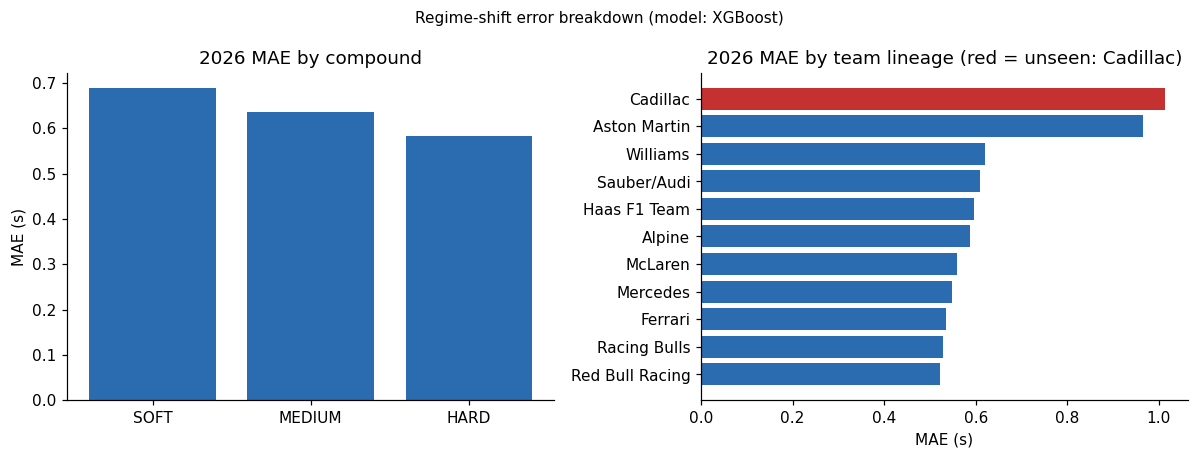

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
axs[0].bar(bd_cmp.compound, bd_cmp.MAE, color='#2b6cb0')
axs[0].set_title('2026 MAE by compound'); axs[0].set_ylabel('MAE (s)')
ct = ['#c53030' if u else '#2b6cb0' for u in bd_team.unseen]
axs[1].barh(list(bd_team.team_lineage)[::-1], list(bd_team.MAE)[::-1], color=ct[::-1])
axs[1].set_title('2026 MAE by team lineage (red = unseen: Cadillac)'); axs[1].set_xlabel('MAE (s)')
fig.suptitle('Regime-shift error breakdown (model: %s)' % best, fontsize=10)
plt.tight_layout(); plt.savefig('figures/07_regime_breakdown.png', dpi=150); plt.show()

**Figure 07.** Error still concentrates where a regime shift predicts. The **unseen** entities are worst: **Cadillac** at 1.01 s and the new **Madrid** circuit at 1.02 s. Both improved a lot over our first iteration (1.54 s and 1.29 s), because the model now gets Cadillac's qualifying pace instead of falling back to an "average team", but they're still clearly the hardest cases. **Aston Martin** (0.97 s) remains the surprise: a *seen* team that's nearly as hard as the brand-new one, because its 2026 car behaves so differently from its 2022-2025 cars. Among compounds **SOFT** is hardest (0.69 s), the fastest-degrading and most situational tyre, and street-style circuits (Monaco, Canada, Las Vegas) top the circuit table.

### 3. Names vs measurements: does measuring pace make the model more robust to the rule change?
Notebook 04 picked the feature set using 2022-2024 only. Now that the choice is locked, we can look at how **every** ablation set (each with its own tuned parameters) handles the 2026 shift. The question: do the features that *measure* pace (qualifying, recent laps) help more in 2026, where team identity goes stale, than in a normal year?

In [6]:
abl = json.load(open('results/ablation.json'))
rows = []
for name, c in abl.items():
    X = encode_features(df, c['groups'], c['team'])
    r = {'feature set': name}
    for te in [2024, 2025, 2026]:
        tr_m, te_m = (df.season < te).to_numpy(), (df.season == te).to_numpy()
        r[te] = metrics(y_all[te_m], make_xgb(**c['xgb_params']).fit(X[tr_m], y_all[tr_m]).predict(X[te_m]))['MAE']
    r['2026 jump'] = r[2026] / np.mean([r[2024], r[2025]]) - 1
    rows.append(r)
nvm = pd.DataFrame(rows).set_index('feature set')
nvm.round(3)

,2024,2025,2026,2026 jump
feature set,,,,
base (team names),0.608,0.589,0.812,0.356
+ qualifying,0.596,0.583,0.789,0.338
+ driver,0.592,0.581,0.768,0.311
+ in-race,0.522,0.492,0.640,0.262
+ circuit,0.495,0.473,0.632,0.306
+ weather (all),0.495,0.469,0.630,0.307
"all, no team names",0.496,0.469,0.629,0.305


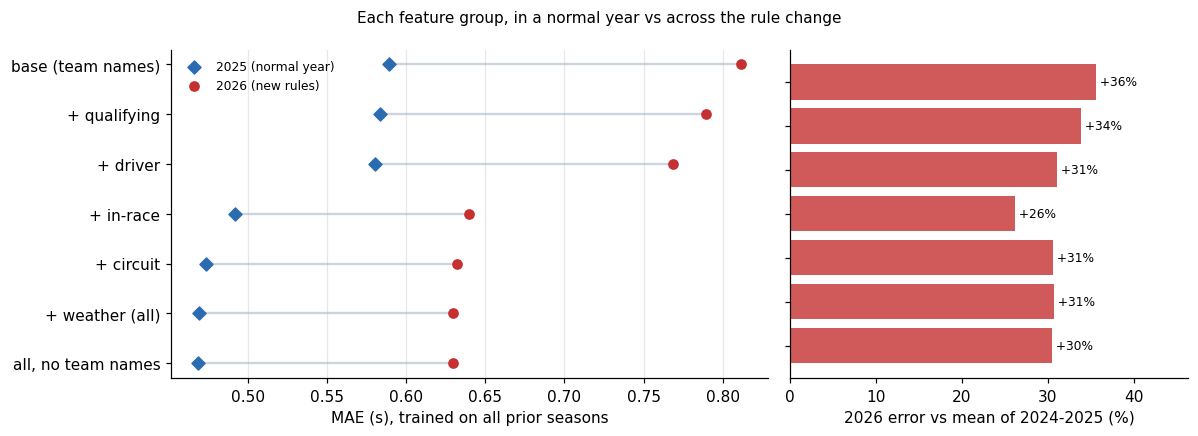

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={'width_ratios': [3, 2]})
yy = np.arange(len(nvm))[::-1]
axs[0].scatter(nvm[2025], yy, marker='D', color='#2b6cb0', label='2025 (normal year)', zorder=3)
axs[0].scatter(nvm[2026], yy, marker='o', color='#c53030', label='2026 (new rules)', zorder=3)
for i, (a, b) in enumerate(zip(nvm[2025], nvm[2026])):
    axs[0].plot([a, b], [yy[i]] * 2, color='#cbd5e0', zorder=1)
axs[0].set_yticks(yy); axs[0].set_yticklabels(nvm.index); axs[0].set_xlabel('MAE (s), trained on all prior seasons')
axs[0].legend(frameon=False, fontsize=8); axs[0].grid(axis='x', alpha=.3)
axs[1].barh(yy, nvm['2026 jump'] * 100, color='#c53030', alpha=.8)
axs[1].set_yticks(yy); axs[1].set_yticklabels([]); axs[1].set_xlabel('2026 error vs mean of 2024-2025 (%)')
for i, v in enumerate(nvm['2026 jump']):
    axs[1].text(v * 100, yy[i], f' +{v:.0%}', va='center', fontsize=8)
axs[1].set_xlim(0, nvm['2026 jump'].max() * 130)
fig.suptitle('Each feature group, in a normal year vs across the rule change', fontsize=10)
plt.tight_layout(); plt.savefig('figures/12_names_vs_measurements.png', dpi=150); plt.show()

**Figure 12.** Read it group by group:
- **Qualifying and driver features help 2026 about four times more than they help a normal year.** Together they cut 2026 error from 0.81 to 0.77 s (-5%) but 2025 error only from 0.59 to 0.58 s (-1%), and the relative jump falls from +36% to +31%. That's the "measure, don't name" idea working exactly where it should: in a stable era the team columns already know each car's pace, but in 2026 that knowledge is stale and the weekly measurement takes over.
- **In-race features help both eras a lot** and push the jump down further, to +26%: reading the race as it unfolds is itself a form of adapting.
- **Circuit features undo some of that** (jump back up to +31%): they help the normal years more than 2026. A likely reason is that two of 2026's circuits (Madrid, Sepang) have no corner map in the data, so the model gets nothing from circuit features exactly where it's on unfamiliar ground.
- **Dropping the team names doesn't make the model more robust**: the measurement-only model degrades exactly as much as the full one (0.629 vs 0.630 s on 2026). The names are redundant, but not harmful.

So measuring pace genuinely helps across the regime shift, but it doesn't close the gap. The next section asks what kind of error is left.

### 4. What kind of error is left? Getting the pace level wrong vs getting the race wrong
A lap prediction can be wrong in two different ways. The model can misjudge **how fast this driver is in this race overall** (a constant offset across all their laps, e.g. thinking Aston Martin is midfield when it's at the back), or it can get the **lap-to-lap evolution** wrong (tyre wear, fuel burn, traffic, energy management). We split each model's errors into those two parts: the per-driver-per-race average residual (the *level* error) and what's left after removing it (the *within-race* error).

In [8]:
def decompose(groups, team, params, test_season):
    X = encode_features(df, groups, team)
    tr_m, te_m = (df.season < test_season).to_numpy(), (df.season == test_season).to_numpy()
    e = y_all[te_m].values - make_xgb(**params).fit(X[tr_m], y_all[tr_m]).predict(X[te_m])
    d = df[te_m][['event', 'driver']].assign(e=e)
    level = d.groupby(['event', 'driver']).e.transform('mean')
    return {'MAE': np.abs(e).mean(), 'level share of squared error': (level ** 2).mean() / (e ** 2).mean(),
            'MAE with level error removed': np.abs(e - level).mean()}
base = abl['base (team names)']
dec = pd.DataFrame({f'{lab} model, {ts}': decompose(g, t, p, ts)
                    for lab, (g, t, p) in {'first-iteration': (base['groups'], base['team'], base['xgb_params']),
                                           'final': (cfg['groups'], cfg['team'], XGB_PARAMS)}.items()
                    for ts in [2025, 2026]}).T
dec.round(3)

,MAE,level share of squared error,MAE with level error removed
"first-iteration model, 2025",0.589,0.213,0.500
"first-iteration model, 2026",0.812,0.494,0.562
"final model, 2025",0.473,0.138,0.430
"final model, 2026",0.627,0.319,0.519


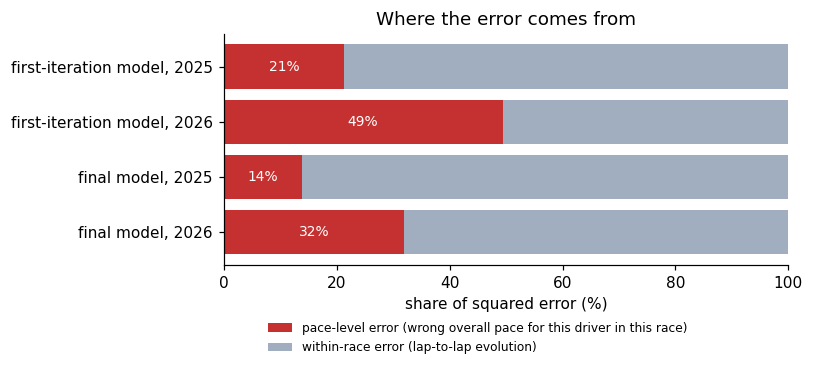

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
yy = np.arange(len(dec))[::-1]
mse_share = dec['level share of squared error']
ax.barh(yy, mse_share * 100, color='#c53030', label='pace-level error (wrong overall pace for this driver in this race)')
ax.barh(yy, (1 - mse_share) * 100, left=mse_share * 100, color='#a0aec0', label='within-race error (lap-to-lap evolution)')
for i, v in enumerate(mse_share):
    ax.text(v * 100 / 2, yy[i], f'{v:.0%}', va='center', ha='center', color='white', fontsize=9)
ax.set_yticks(yy); ax.set_yticklabels(dec.index); ax.set_xlabel('share of squared error (%)'); ax.set_xlim(0, 100)
ax.legend(frameon=False, fontsize=8, loc='upper center', bbox_to_anchor=(0.45, -0.2), ncol=1)
ax.set_title('Where the error comes from')
plt.tight_layout(); plt.savefig('figures/13_error_decomposition.png', dpi=150); plt.show()

**Figure 13.** This is the clearest picture we have of what the regulation change did to our model:
- In a normal year (2025), most error is **within-race**: the model knows roughly how fast everyone is and misses the lap-to-lap detail.
- In 2026 the first-iteration model's error is **half pace-level error** (49% vs 21% in 2025): it simply didn't know how fast each car was, because team names from 2022-2025 described different cars.
- Our measurement features **cut that pace-level share from 49% to 32%** in 2026. That's qualifying and recent pace doing their job.
- But even with the level error removed entirely, 2026 laps are still harder to predict (MAE 0.52 vs 0.43 s in 2025). So the new rules didn't just reshuffle the pecking order; they changed **how a race unfolds lap by lap**, which fits what we saw in notebook 02's stint-pace curves (flat stints that suddenly speed up) and points at 2026 energy management. Notebook 07 digs into that.

### 5. Can you even tell a 2026 lap from a 2025 lap? (adversarial validation)
A standard check for distribution shift: train a classifier to tell 2025 laps from 2026 laps using the model's inputs. An AUC near 0.5 means the inputs look the same in both years (any shift is in the *relationship* between inputs and lap time); an AUC near 1 means the inputs themselves moved. We leave out the team columns (Cadillac would give 2026 away instantly) and the circuit and weather features (which mostly fingerprint the calendar), and we split by race so the classifier can't memorise a race.

In [10]:
sub = df[df.season.isin([2025, 2026])].reset_index(drop=True)
is26 = (sub.season == 2026).astype(int).values
cols = [c for g in ['base', 'quali', 'driver', 'race'] for c in FEATURE_GROUPS[g]]
grp = pd.factorize(sub.season.astype(str) + sub.event)[0]
def adv_auc(X):
    p = np.zeros(len(X))
    for a, b in GroupKFold(n_splits=5).split(X, is26, grp):
        clf = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, n_jobs=-1, random_state=SEED)
        p[b] = clf.fit(X.iloc[a], is26[a]).predict_proba(X.iloc[b])[:, 1]
    return roc_auc_score(is26, p)
print('AUC, inputs only:             %.3f' % adv_auc(sub[cols]))
print('AUC, inputs + the lap delta:  %.3f' % adv_auc(sub[cols].assign(lap_delta_s=sub.lap_delta_s)))
clf = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, n_jobs=-1, random_state=SEED).fit(sub[cols], is26)
pd.Series(clf.feature_importances_, cols).sort_values(ascending=False).head(6).round(3).to_frame('importance')

AUC, inputs only:             0.586


AUC, inputs + the lap delta:  0.584


,importance
team_quali_gap_pct,0.165
air_temp_c,0.152
track_temp_c,0.128
recent_pace,0.115
quali_rank,0.084
quali_speed_trap_delta,0.066


**Read:** an AUC of ~0.59 means individual 2026 laps look only mildly different from 2025 laps. The features that give 2026 away are the ones that measure the field's spread (`team_quali_gap_pct`, `recent_pace`, `quali_rank`), plus temperatures (a different calendar and weather year). Adding the lap delta itself doesn't help the classifier either. So the 2026 shift isn't a handful of bizarre laps a filter could catch; it's a subtle change spread across every lap, which is precisely what makes it dangerous: nothing in a single lap warns you that the model's assumptions no longer hold.

### 6. Is the model honest about its uncertainty under the shift?
A model that's wrong is bad; a model that's wrong *and confident* is worse. We build **split-conformal prediction intervals**: train on all seasons up to Y-2, take the 90th percentile of absolute errors on season Y-1 as the interval half-width, and check what fraction of season Y's laps actually land inside. We run it twice: a normal year (train 2022-2023, calibrate on 2024, test 2025) as the control, and the regime shift (train 2022-2024, calibrate on 2025, test 2026). One caveat: conformal coverage guarantees assume the calibration and test laps are exchangeable, and laps cluster by race, so even in a normal year coverage won't be exactly 90%.

In [11]:
def conformal(train_to, cal_season, test_season):
    tr_m = (df.season <= train_to).to_numpy()
    m = make_xgb(**XGB_PARAMS).fit(X_all[tr_m], y_all[tr_m])
    res = np.abs(y_all.values - m.predict(X_all))
    q = np.quantile(res[(df.season == cal_season).to_numpy()], 0.9)
    te_m = (df.season == test_season).to_numpy()
    return q, res, te_m
rows = []
for label, (a, b, c) in {'normal year (test 2025)': (2023, 2024, 2025), 'regime shift (test 2026)': (2024, 2025, 2026)}.items():
    q, res, te_m = conformal(a, b, c)
    rows.append({'setting': label, 'interval half-width (s)': q, 'coverage': (res[te_m] <= q).mean(),
                 'half-width needed for 90%': np.quantile(res[te_m], 0.9)})
pd.DataFrame(rows).set_index('setting').round(3)

,interval half-width (s),coverage,half-width needed for 90%
setting,,,
normal year (test 2025),1.043,0.905,1.019
regime shift (test 2026),1.015,0.817,1.368


**The control works:** in a normal year the intervals cover 90.5% of laps, right on the promised 90%. In 2026 the identical procedure covers only **81.7%**: the model is wrong more often than it *thinks* it is. Covering 90% of 2026 laps would need a +/-1.37 s band instead of +/-1.02 s. Can we fix that as the season goes on? Below we keep the model fixed and only **recalibrate the interval width** before each 2026 race, using the errors from the 2026 races already run.

Mean per-race coverage: static 81.8% | recalibrated on earlier 2026 races 89.6%


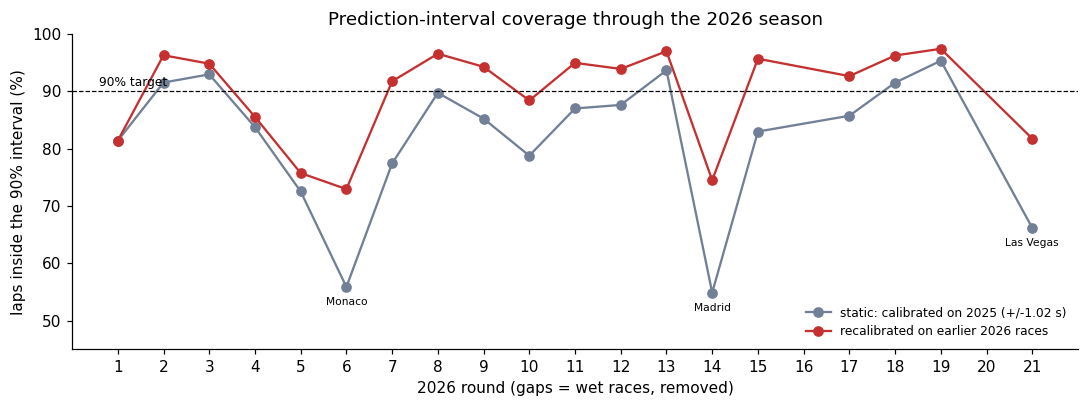

,round,race,static,recalibrated,width
0,1,Australian,0.814,0.814,1.015
1,2,Chinese,0.916,0.963,1.377
2,3,Japanese,0.930,0.948,1.183
3,4,Miami,0.838,0.856,1.080
4,5,Canadian,0.725,0.757,1.140
5,6,Monaco,0.559,0.730,1.343
6,7,Barcelona,0.774,0.918,1.553
7,8,Austrian,0.898,0.966,1.536
8,9,British,0.853,0.943,1.473
9,10,Belgian,0.788,0.884,1.449


In [12]:
q, res, te_m = conformal(2024, 2025, 2026)
d = df[te_m][['round', 'circuit']].assign(r=res[te_m])
rows, seen = [], []
for rd, g in d.groupby('round'):
    q_now = np.quantile(np.concatenate(seen), 0.9) if seen else q
    rows.append({'round': rd, 'race': g.circuit.iloc[0],
                 'static': (g.r <= q).mean(), 'recalibrated': (g.r <= q_now).mean(), 'width': q_now})
    seen.append(g.r.values)
cov = pd.DataFrame(rows)
print('Mean per-race coverage: static %.1f%% | recalibrated on earlier 2026 races %.1f%%'
      % (cov.static.mean() * 100, cov.recalibrated.mean() * 100))
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(cov['round'], cov.static * 100, marker='o', color='#718096', label=f'static: calibrated on 2025 (+/-{q:.2f} s)')
ax.plot(cov['round'], cov.recalibrated * 100, marker='o', color='#c53030', label='recalibrated on earlier 2026 races')
ax.axhline(90, color='black', lw=.8, ls='--'); ax.text(0.6, 91, '90% target', fontsize=8)
for _, r in cov[cov.static < 0.7].iterrows():
    ax.annotate(r.race, (r['round'], r.static * 100), textcoords='offset points', xytext=(0, -12), ha='center', fontsize=7)
ax.set_xlabel('2026 round (gaps = wet races, removed)'); ax.set_ylabel('laps inside the 90% interval (%)'); ax.set_ylim(45, 100)
ax.set_xticks(range(1, int(cov['round'].max()) + 1))
ax.set_title('Prediction-interval coverage through the 2026 season'); ax.legend(frameon=False, fontsize=8, loc='lower right')
plt.tight_layout(); plt.savefig('figures/14_interval_coverage_2026.png', dpi=150); plt.show()
cov.round(3)

**Figure 14.** Calibrated on 2025, the "90%" intervals only cover ~82% of the average 2026 race, and as little as ~55% at Monaco and the brand-new Madrid circuit and ~66% at Las Vegas. Recalibrating the width before each race on the 2026 races already run brings average coverage back to ~90% (89.6%), at the cost of a wider band (from about +/-1.0 s to about +/-1.4 s). The unusual circuits still fall short even then (Monaco ~73%, Madrid ~75%, Las Vegas ~82%), because one global width can't know that some tracks are harder than others. That's a really practical lesson for anyone deploying a model through a regime change: **you can restore honest uncertainty almost immediately, even while the point predictions stay stubbornly worse.**

### 7. Robustness: remove the races run after both titles were decided
Notebook 02 found no sign that champion teams ease off once both titles are settled, so we keep those 10 races. As a robustness check we rerun the drift-vs-shift comparison with them removed from **both** training and test data. If the conclusions hold either way, they don't depend on that choice.

In [13]:
keep = ~df.post_clinch.astype(bool)
rows = []
for tr_seasons, te_season in transitions:
    for label, m in [('all races', pd.Series(True, index=df.index)), ('post-clinch removed', keep)]:
        ev = evaluate_split(df, X_all, y_all, df.season.isin(tr_seasons) & m, (df.season == te_season) & m,
                            XGB_PARAMS, models=['XGBoost'])
        rows.append({'test_season': te_season, 'data': label, 'MAE': ev.loc['XGBoost', 'MAE']})
rob = pd.DataFrame(rows).pivot(index='test_season', columns='data', values='MAE')
rob.loc['2026 vs mean(2024, 2025)'] = rob.loc[2026] / rob.loc[[2024, 2025]].mean() - 1
print('XGBoost MAE (s); last row = relative jump at 2026')
rob.round(3)

XGBoost MAE (s); last row = relative jump at 2026


data,all races,post-clinch removed
test_season,,
2024,0.495,0.504
2025,0.473,0.493
2026,0.627,0.626
"2026 vs mean(2024, 2025)",0.295,0.256


**Read:** the two columns tell the same story. The 2026 jump is +30% with every race and +26% with the post-clinch races removed, and the normal years barely move, so the regime-shift result doesn't hinge on whether we keep the races run after the titles were decided.